In [1]:
from torch import embedding
import torch
import torch.nn as nn

embeddings=nn.Embedding(
    num_embeddings=1000,
    embedding_dim=4
)
print(embeddings)

Embedding(1000, 4)


In [5]:
print(embeddings.weight)
print(embeddings.weight.shape)
print("Total parameters:", embeddings.weight.numel())

Parameter containing:
tensor([[ 0.7677, -0.1162,  0.5992,  0.9304],
        [-0.9186, -1.0087, -0.5650,  0.6412],
        [ 0.0539,  0.6136,  0.1971,  0.7451],
        ...,
        [-0.8602, -1.4331, -0.2277,  1.3846],
        [-0.2713,  1.8105, -2.6454,  1.3880],
        [ 0.9229, -0.0724,  1.8782, -0.2070]], requires_grad=True)
torch.Size([1000, 4])
Total parameters: 4000


In [7]:
input_ids = torch.tensor([
    [0, 2, 4],
    [1, 3, 0]
])

output = embeddings(input_ids)

print(output.shape)

torch.Size([2, 3, 4])


In [13]:
import torch
import torch.nn as nn

embedding=nn.Embedding(
    num_embeddings=100,
    embedding_dim=8
)

input_ids=torch.tensor([5,10,20,30])
output=embedding(input_ids)
print(input_ids)
print(output)
print(output.shape)
print(embedding.weight.requires_grad)

tensor([ 5, 10, 20, 30])
tensor([[-1.8178, -1.7769, -1.2607, -0.8130,  0.2796,  1.4143,  0.4141, -0.9831],
        [ 0.1272,  0.2087,  1.0839, -1.3715, -0.6552,  0.0552, -1.0512, -0.5636],
        [ 0.7820, -0.6158, -2.0379, -1.1174,  0.9627, -0.4699,  1.8016, -2.7985],
        [ 0.5543,  0.3225,  1.0408,  0.4116,  0.0552, -0.0453, -0.7838, -0.0129]],
       grad_fn=<EmbeddingBackward0>)
torch.Size([4, 8])
True


In [14]:
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from transformers import AutoTokenizer, AutoModel
from sentence_transformers import SentenceTransformer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

MODEL_NAME = "distilbert/distilgpt2"
SENTENCE_MODEL_NAME = "sentence-transformers/all-MiniLM-L6-v2"

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

print("PyTorch:", torch.__version__)
print("Device:", DEVICE)

PyTorch: 2.15.0+cpu
Device: cpu


In [15]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
model = AutoModel.from_pretrained(MODEL_NAME).to(DEVICE)
model.eval()

# GPT-2 tokenizers commonly have no separate PAD token.
# This alias is only for batching; the attention mask identifies padding positions.
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

embedding_layer = model.get_input_embeddings()
embedding_matrix = embedding_layer.weight

print("Model:", MODEL_NAME)
print("Vocabulary size:", model.config.vocab_size)
print("Hidden dimension:", model.config.hidden_size)
print("Transformer layers:", model.config.n_layer)
print("Attention heads:", model.config.n_head)
print("Maximum position embeddings:", model.config.n_positions)
print("Token embedding matrix:", tuple(embedding_matrix.shape))

Loading weights:   0%|          | 0/76 [00:00<?, ?it/s]

Model: distilbert/distilgpt2
Vocabulary size: 50257
Hidden dimension: 768
Transformer layers: 6
Attention heads: 12
Maximum position embeddings: 1024
Token embedding matrix: (50257, 768)


In [16]:
text = "Artificial intelligence is changing the way people work."

inputs = tokenizer(text, return_tensors="pt")
inputs = {key: value.to(DEVICE) for key, value in inputs.items()}
input_ids = inputs["input_ids"]

tokens = tokenizer.convert_ids_to_tokens(input_ids[0].detach().cpu().tolist())

print("Text:", text)
print("Tokens:", tokens)
print("Input IDs:", input_ids)
print("Input shape:", tuple(input_ids.shape))

Text: Artificial intelligence is changing the way people work.
Tokens: ['Art', 'ificial', 'Ġintelligence', 'Ġis', 'Ġchanging', 'Ġthe', 'Ġway', 'Ġpeople', 'Ġwork', '.']
Input IDs: tensor([[8001, 9542, 4430,  318, 5609,  262,  835,  661,  670,   13]])
Input shape: (1, 10)


In [17]:
with torch.no_grad():
    token_embeddings = embedding_layer(input_ids)

print("Whole vocabulary matrix:", tuple(embedding_matrix.shape))
print("This input's token embeddings:", tuple(token_embeddings.shape))
print("First token vector shape:", tuple(token_embeddings[0, 0].shape))
print("First token vector (first 10 values):")
print(token_embeddings[0, 0, :10].detach().cpu())

Whole vocabulary matrix: (50257, 768)
This input's token embeddings: (1, 10, 768)
First token vector shape: (768,)
First token vector (first 10 values):
tensor([ 0.0252, -0.2403,  0.1496, -0.1516, -0.0034, -0.0011, -0.2193, -0.0215,
         0.0644,  0.1111])


In [18]:
token_vectors = token_embeddings[0].detach().cpu().numpy()

token_table = pd.DataFrame({
    "token": tokens,
    "token_id": input_ids[0].detach().cpu().tolist(),
    "dimensions": [token_vectors.shape[1]] * len(tokens),
    "first_8_values": [np.round(vector[:8], 4).tolist() for vector in token_vectors],
})

display(token_table)

,token,token_id,dimensions,first_8_values
0,Art,8001,768,"[0.0252, -0.2403, 0.1496, -0.1516, -0.0034, -0..."
1,ificial,9542,768,"[0.0962, -0.0387, 0.0813, -0.2289, -0.0869, 0...."
2,Ġintelligence,4430,768,"[-0.0618, 0.0045, 0.025, 0.0168, 0.0682, 0.001..."
3,Ġis,318,768,"[-0.0006, 0.0075, 0.0307, -0.1343, -0.1336, 0...."
4,Ġchanging,5609,768,"[0.1061, -0.0664, -0.0057, 0.048, -0.2004, -0...."
5,Ġthe,262,768,"[-0.0732, 0.0183, 0.0231, 0.0546, -0.0285, -0...."
6,Ġway,835,768,"[-0.1968, -0.0507, 0.0138, -0.1349, -0.0125, -..."
7,Ġpeople,661,768,"[-0.1518, 0.12, 0.0461, 0.0955, -0.0036, 0.111..."
8,Ġwork,670,768,"[-0.0936, -0.0776, 0.1045, -0.2189, -0.086, 0...."
9,.,13,768,"[0.04, -0.0202, 0.0025, 0.0594, 0.0515, -0.077..."


In [19]:
first_token_vector = token_embeddings[0, 0]

print("Min:", first_token_vector.min().item())
print("Max:", first_token_vector.max().item())
print("Mean:", first_token_vector.mean().item())
print("Standard deviation:", first_token_vector.std().item())
print("L2 norm:", torch.linalg.vector_norm(first_token_vector).item())

Min: -0.5323447585105896
Max: 0.37524327635765076
Mean: -0.004449157044291496
Standard deviation: 0.1291751116514206
L2 norm: 3.5795984268188477


In [20]:
with torch.no_grad():
    outputs = model(**inputs)

last_hidden_states = outputs.last_hidden_state

print("Initial token embeddings:", tuple(token_embeddings.shape))
print("Contextual token states:", tuple(last_hidden_states.shape))

initial_vector = token_embeddings[0, 0]
contextual_vector = last_hidden_states[0, 0]

similarity_initial_contextual = torch.nn.functional.cosine_similarity(
    initial_vector.unsqueeze(0),
    contextual_vector.unsqueeze(0)
)

print("Cosine similarity for first token:", similarity_initial_contextual.item())

Initial token embeddings: (1, 10, 768)
Contextual token states: (1, 10, 768)
Cosine similarity for first token: -0.11263735592365265


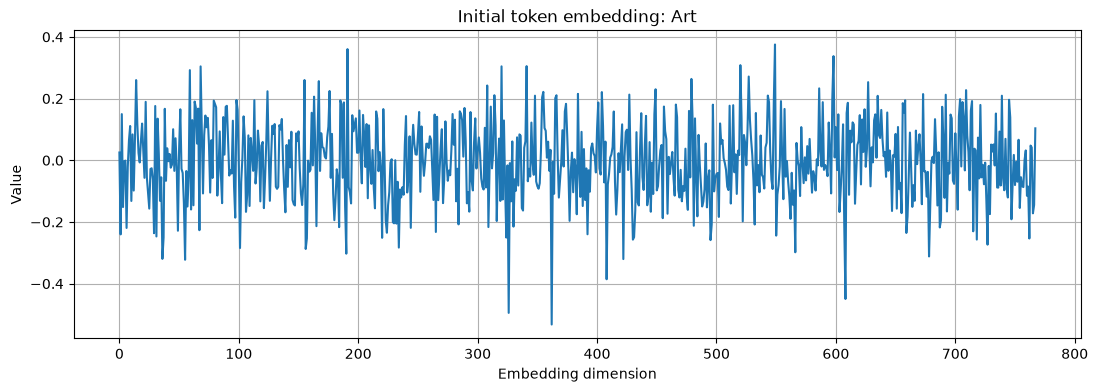

In [21]:
vector = token_embeddings[0, 0].detach().cpu().numpy()

plt.figure(figsize=(13, 4))
plt.plot(vector)
plt.title(f"Initial token embedding: {tokens[0]}")
plt.xlabel("Embedding dimension")
plt.ylabel("Value")
plt.grid(True)
plt.show()

In [22]:
# AutoModel for this checkpoint is GPT2Model, which exposes the learned position table as wpe.
position_embedding_layer = getattr(model, "wpe", None)

if position_embedding_layer is None:
    raise AttributeError(
        "This checkpoint's model does not expose a GPT-2 wpe layer. "
        "Inspect model.named_modules() and model.config before adapting this cell."
    )

position_embedding_matrix = position_embedding_layer.weight

print("Position embedding matrix shape:", tuple(position_embedding_matrix.shape))
print("Position embedding layer:", position_embedding_layer)

Position embedding matrix shape: (1024, 768)
Position embedding layer: Embedding(1024, 768)


In [24]:
sequence_length = input_ids.shape[1]
position_ids = torch.arange(sequence_length, device=DEVICE).unsqueeze(0)

with torch.no_grad():
    position_vectors = position_embedding_layer(position_ids)

print("Position IDs:", position_ids)
print("Position vectors shape:", tuple(position_vectors.shape))

position_table = pd.DataFrame({
    "position": position_ids[0].detach().cpu().tolist(),
    "first_8_values": [
        np.round(row[:8], 4).tolist()
        for row in position_vectors[0].detach().cpu().numpy()
    ]
})

print(position_table)

Position IDs: tensor([[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]])
Position vectors shape: (1, 10, 768)
   position                                     first_8_values
0         0  [-0.0188, -0.1974, 0.004, 0.0113, 0.0638, -0.1...
1         1  [0.024, -0.0538, -0.0949, -0.0129, -0.0101, 0....
2         2  [0.0042, -0.0848, 0.0545, -0.0047, -0.0261, 0....
3         3  [-0.0003, -0.0738, 0.1055, 0.0007, -0.0156, 0....
4         4  [0.0076, -0.0251, 0.127, -0.0063, -0.0124, 0.0...
5         5  [0.0096, -0.0339, 0.1312, -0.0039, -0.0102, 0....
6         6  [0.0027, -0.0205, 0.1196, -0.0029, -0.009, 0.0...
7         7  [0.0025, -0.0032, 0.1174, -0.0022, -0.0032, 0....
8         8  [-0.0012, -0.0018, 0.111, -0.0048, -0.0086, 0....
9         9  [0.0049, 0.0021, 0.1178, -0.0001, -0.0057, 0.0...


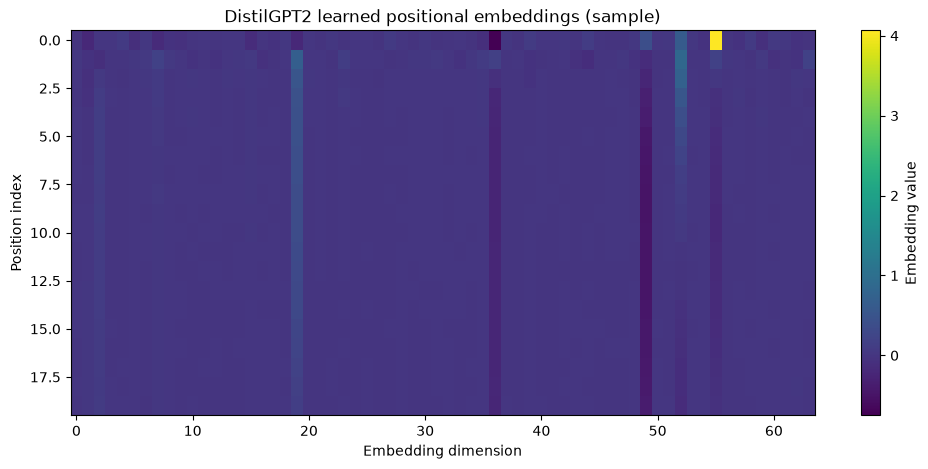

In [25]:
positions_to_show = min(20, position_embedding_matrix.shape[0])
dimensions_to_show = min(64, position_embedding_matrix.shape[1])

position_sample = (
    position_embedding_matrix[:positions_to_show, :dimensions_to_show]
    .detach().cpu().numpy()
)

plt.figure(figsize=(12, 5))
plt.imshow(position_sample, aspect="auto")
plt.colorbar(label="Embedding value")
plt.title("DistilGPT2 learned positional embeddings (sample)")
plt.xlabel("Embedding dimension")
plt.ylabel("Position index")
plt.show()

In [26]:
sentence_model = SentenceTransformer(SENTENCE_MODEL_NAME, device=DEVICE)

sentences = [
    "A dog is playing in the garden.",
    "A puppy is running outside.",
    "The stock market fell sharply today.",
    "A child is playing with a ball outdoors.",
]

sentence_embeddings = sentence_model.encode(
    sentences,
    convert_to_numpy=True,
    normalize_embeddings=True,
    show_progress_bar=False
)

print("Sentence embedding matrix shape:", sentence_embeddings.shape)
print("Vector dimensions:", sentence_embeddings.shape[1])

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Sentence embedding matrix shape: (4, 384)
Vector dimensions: 384


In [27]:
sentence_a = "A dog is playing in the garden."
sentence_b = "A puppy is running outside."

pair_embeddings = sentence_model.encode(
    [sentence_a, sentence_b],
    convert_to_numpy=True,
    normalize_embeddings=True
)

pair_similarity = float(pair_embeddings[0] @ pair_embeddings[1])

print("Sentence A:", sentence_a)
print("Sentence B:", sentence_b)
print("Cosine similarity:", round(pair_similarity, 4))

Sentence A: A dog is playing in the garden.
Sentence B: A puppy is running outside.
Cosine similarity: 0.4784


In [29]:
similarity_matrix = cosine_similarity(sentence_embeddings)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=[f"S{i+1}" for i in range(len(sentences))],
    columns=[f"S{i+1}" for i in range(len(sentences))]
)

print(similarity_df.round(3))

       S1     S2     S3     S4
S1  1.000  0.478  0.044  0.362
S2  0.478  1.000  0.108  0.282
S3  0.044  0.108  1.000  0.020
S4  0.362  0.282  0.020  1.000


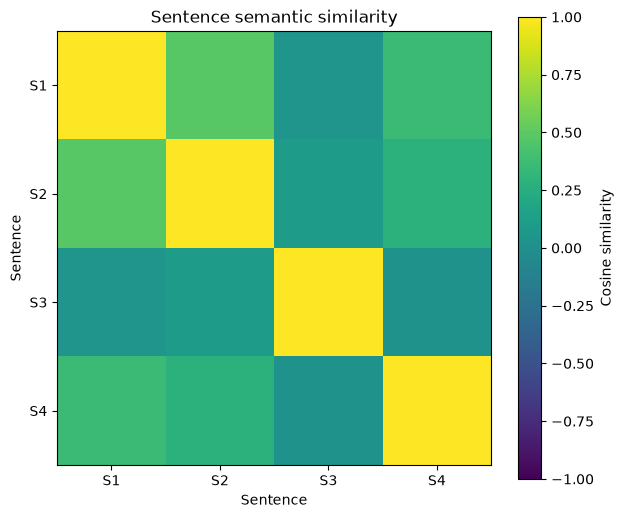

S1: A dog is playing in the garden.
S2: A puppy is running outside.
S3: The stock market fell sharply today.
S4: A child is playing with a ball outdoors.


In [30]:
plt.figure(figsize=(7, 6))
plt.imshow(similarity_matrix, vmin=-1, vmax=1)
plt.colorbar(label="Cosine similarity")
plt.xticks(range(len(sentences)), [f"S{i+1}" for i in range(len(sentences))])
plt.yticks(range(len(sentences)), [f"S{i+1}" for i in range(len(sentences))])
plt.title("Sentence semantic similarity")
plt.xlabel("Sentence")
plt.ylabel("Sentence")
plt.show()

for i, sentence in enumerate(sentences):
    print(f"S{i+1}: {sentence}")

In [31]:
# PCA is a fast linear dimensionality-reduction method.
pca = PCA(n_components=2)
pca_vectors = pca.fit_transform(sentence_embeddings)

pca_df = pd.DataFrame({
    "x": pca_vectors[:, 0],
    "y": pca_vectors[:, 1],
    "sentence": sentences
})

display(pca_df)

,x,y,sentence
0,-0.364714,-0.232780,A dog is playing in the garden.
1,-0.223188,-0.473682,A puppy is running outside.
2,0.906659,0.028212,The stock market fell sharply today.
3,-0.318757,0.678250,A child is playing with a ball outdoors.


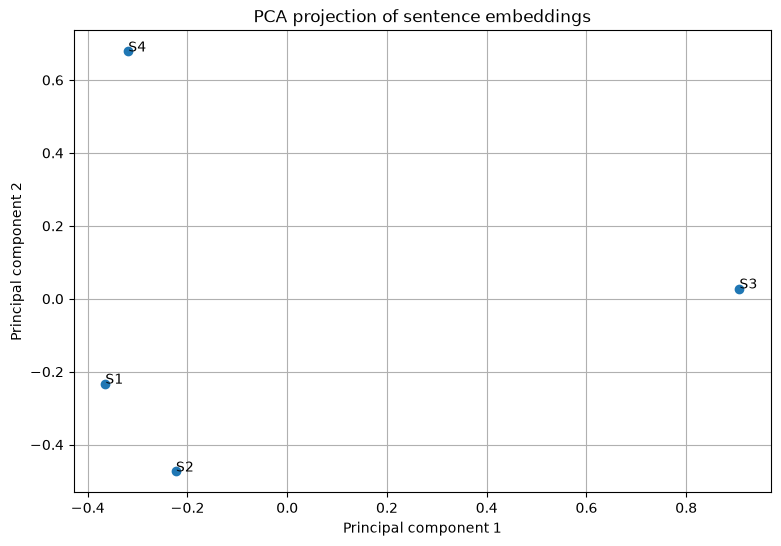

In [32]:
plt.figure(figsize=(9, 6))
plt.scatter(pca_vectors[:, 0], pca_vectors[:, 1])

for i, sentence in enumerate(sentences):
    plt.annotate(f"S{i+1}", (pca_vectors[i, 0], pca_vectors[i, 1]))

plt.title("PCA projection of sentence embeddings")
plt.xlabel("Principal component 1")
plt.ylabel("Principal component 2")
plt.grid(True)
plt.show()

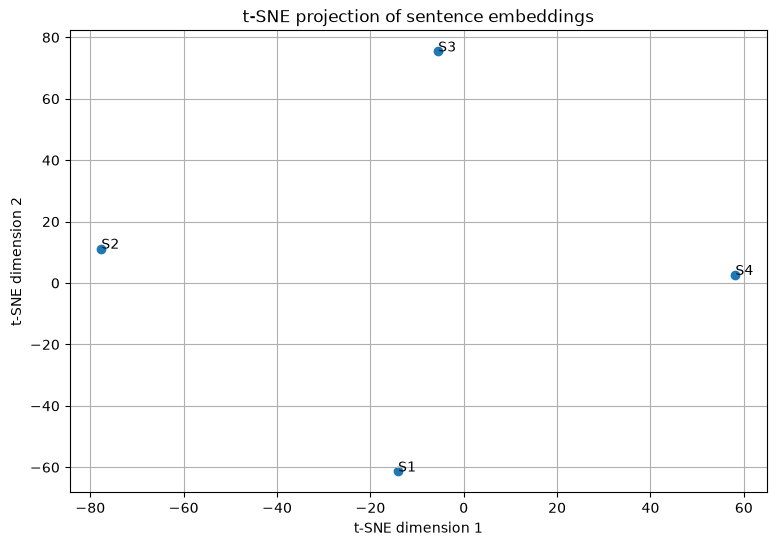

In [33]:
if len(sentence_embeddings) >= 4:
    perplexity = min(5, len(sentence_embeddings) - 1)

    tsne = TSNE(
        n_components=2,
        perplexity=perplexity,
        init="random",
        learning_rate="auto",
        random_state=42
    )

    tsne_vectors = tsne.fit_transform(sentence_embeddings)

    plt.figure(figsize=(9, 6))
    plt.scatter(tsne_vectors[:, 0], tsne_vectors[:, 1])

    for i in range(len(sentences)):
        plt.annotate(f"S{i+1}", (tsne_vectors[i, 0], tsne_vectors[i, 1]))

    plt.title("t-SNE projection of sentence embeddings")
    plt.xlabel("t-SNE dimension 1")
    plt.ylabel("t-SNE dimension 2")
    plt.grid(True)
    plt.show()
else:
    print("Add at least 4 sentences to run this t-SNE example.")